## 📓 Notebook 06: Datetime Features

**Skills practiced:** `pd.to_datetime()`, the `.dt` accessor, boolean flags with `.isin()`, time-since-start columns.

**Goal:** Turn one raw timestamp into hour, day of week, month, weekend flag, rush-hour flag, and days-since-start, and plot ride count by hour.

In [10]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt

from sklearn.metrics import root_mean_squared_error
from sklearn.ensemble import RandomForestRegressor

In [11]:
x_train=pd.read_csv('../data/processed/stage_3/x_train_poly.csv')
x_test=pd.read_csv('../data/processed/stage_3/x_test_poly.csv')
y_train=pd.read_csv('../data/processed/y_train.csv')
y_test=pd.read_csv('../data/processed/y_test.csv')
df=pd.read_csv('../data/raw/store_sharing.csv')

In [12]:
x_train_raw=x_train.copy()
x_test_raw=x_test.copy()

In [13]:
c = pd.to_datetime(df['timestamp'])

for d in (x_train, x_test):
    t = c.loc[d.index]
    d['hour'] = t.dt.hour
    d['day_of_week'] = t.dt.dayofweek
    d['month'] = t.dt.month

In [14]:
start = c.min()

for d in (x_train, x_test):
    t = c.loc[d.index]
    d['is_weekend'] = (t.dt.dayofweek >= 5).astype(int)
    d['is_rush_hour'] = t.dt.hour.isin([7, 8, 9, 16, 17, 18, 19]).astype(int)
    d['days_since_start'] = (t - start).dt.days

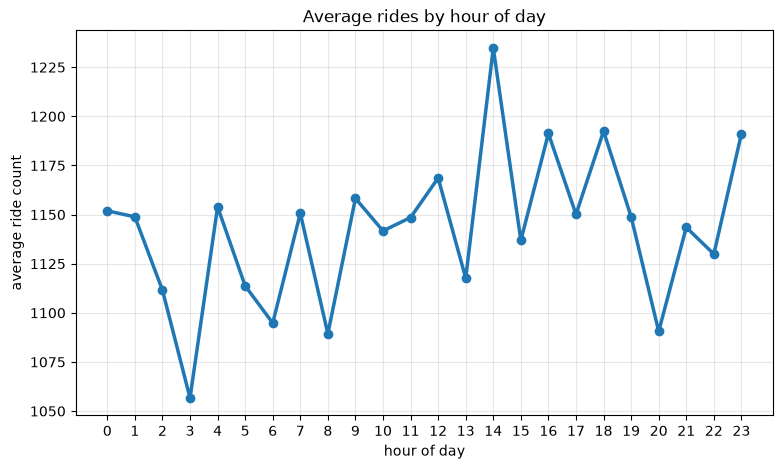

In [15]:
plot_df = x_train.join(y_train['cnt'])

ax = plot_df.groupby(['hour'])['cnt'].mean().plot(figsize=(9, 5),marker='o', linewidth=2.5)
ax.set_xticks(range(24))
ax.set_xlabel('hour of day')
ax.set_ylabel('average ride count')
ax.set_title('Average rides by hour of day')
ax.grid(alpha=0.3)

plt.savefig('../outputs/figures/hour_of_day.png', dpi=200, bbox_inches='tight')
plt.show()

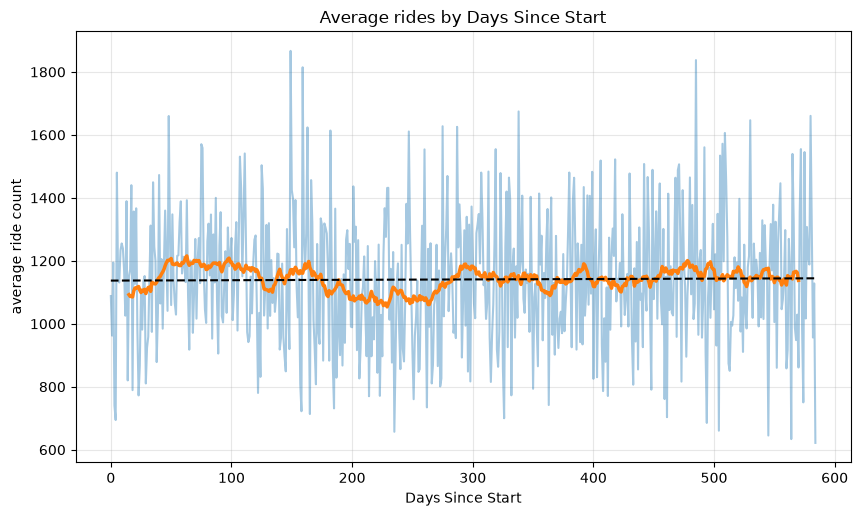

In [16]:
plot_df = x_train.join(y_train['cnt'])
daily = plot_df.groupby(['days_since_start'])['cnt'].mean()
full_range = range(plot_df['days_since_start'].min(), plot_df['days_since_start'].max() + 1)
daily = daily.reindex(full_range)

ax = daily.plot(alpha=0.4, figsize=(10, 5.6))
daily.rolling(30, center=True).mean().plot(ax=ax, linewidth=2.5)
ax.set_xlabel('Days Since Start')
ax.set_ylabel('average ride count')
ax.set_title('Average rides by Days Since Start')
ax.grid(alpha=0.3)

slope, intercept = np.polyfit(daily.dropna().index, daily.dropna().values, 1)
ax.plot(daily.index, slope * daily.index + intercept, color='black', linestyle='--')

plt.savefig('../outputs/figures/days_since_start.png', dpi=200, bbox_inches='tight')
plt.show()

In [19]:
for name, (tr, te) in {
    'raw': (x_train_raw, x_test_raw),
    'polynomial featured': (x_train, x_test),
}.items():
    rf = RandomForestRegressor(n_estimators=250, random_state=42, n_jobs=-1)
    rf.fit(tr, y_train['cnt'])
    p1= rf.predict(te)
    print(name, round(root_mean_squared_error(y_test['cnt'],p1),2))

raw 257.6
polynomial featured 298.34


## 🐞 Known issue: can you find the bug?

The feature-engineering step in this notebook behaves strangely, and I haven't fixed it yet.

| Table | Test RMSE (lower is better) |
|-------|-----------------------------|
| raw | 257.6 |
| polynomial featured | 298.34 |

**What looks wrong:** the polynomial-featured table is about 40 points *worse* than raw. A random forest can ignore useless columns, so extra features should not hurt this much. In the full pipeline script, the engineered table scores better than raw, so this notebook is likely doing something different.

**Your challenge:** find the cause, fix it, and show that the engineered table matches or beats raw.

### Hints (read one at a time)

1. **Row alignment.** Are the new time columns attached to the right rows, or matched by position or label after the data was reloaded or shuffled? Misaligned features give plausible-looking but scrambled inputs.
2. **Notebook state.** Did a cell run twice or out of order? Re-running a cell that adds columns in place can leave duplicate or stale columns. Try *Kernel > Restart & Run All*.
3. **Train/test mismatch.** Do the train and test tables have exactly the same columns, in the same order, built the same way?
4. **Scaled vs unscaled values.** Were any features created from already-scaled columns in one table but unscaled columns in the other?
5. **Redundant columns.** Polynomial terms on highly correlated inputs add many near-duplicate columns. Does dropping them change the score?
6. **Noise.** Fix `random_state` and average over several seeds before trusting any single score.

### How to submit a fix

- Explain the root cause in one or two sentences.
- Show the before and after RMSE with the same seed.
- Keep the fix fit-on-train-only, so no test information leaks into training.

Open a pull request or an issue with your findings. 🙌

In [18]:
x_train.to_csv('../data/processed/x_train.csv')
x_test.to_csv('../data/processed/x_test.csv')
joblib.dump(rf, '../models/stage3_model.joblib')

['../models/stage3_model.joblib']